# Scratch: week of Nov 2-8
Exploration notebook. Data comes from the company app (Supabase); credentials load from `.env` in the project root.
Setup matches the weekly report: every tracked week, with the reporting week last.

In [1]:
import sys
from datetime import timedelta
sys.path.insert(0, "../src")
from reusables import *
from supabase_pull import load_waste, count_jobs, pull
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Edit this each week --------------------------------------------------
# Every reporting week since tracking began: Monday -> jobs that week.
# Add the new week at the bottom. The last line is the reporting week.
# None = count jobs from the app.
JOBS_BY_WEEK = {
    "2026-10-12": 36,
    "2026-10-19": 32,
    "2026-10-26": 21,
    "2026-11-02": 24,
}
AVG_LABEL = "Avg of prior weeks"
# ---------------------------------------------------------------------------

def week_label(monday):
    sunday = monday + timedelta(days=6)
    end = f"{sunday:%b} {sunday.day}" if sunday.month != monday.month else f"{sunday.day}"
    return f"Week of {monday:%b} {monday.day}-{end}"

mondays    = [pd.Timestamp(d).date() for d in JOBS_BY_WEEK]
week_start = mondays[-1]
week_end   = week_start + timedelta(days=7)          # following Monday (not included)

# App timestamps are UTC: pull a day either side, then filter on the local date
df = load_waste(str(mondays[0] - timedelta(days=1)), end=str(week_end + timedelta(days=1)))
df["kind"] = df["kind"].replace({"Lost Item": "Item Search"})

weeks, jobs_by_week = {}, {}                          # every week so far, oldest first
for monday, jobs in zip(mondays, JOBS_BY_WEEK.values()):
    sunday = monday + timedelta(days=6)
    label = week_label(monday)
    weeks[label] = df[(df["incident_date"] >= monday) & (df["incident_date"] <= sunday)]
    jobs_by_week[label] = jobs if jobs is not None else count_jobs(str(monday), str(sunday))

labels          = list(weeks)
WEEK_LABEL      = labels[-1]
LAST_WEEK_LABEL = labels[-2]
this_week       = weeks[WEEK_LABEL]
WEEK_JOBS       = jobs_by_week[WEEK_LABEL]
prior_end       = week_start - timedelta(days=1)
PRIOR_SPAN      = f"{mondays[0]:%b} {mondays[0].day} - {prior_end:%b} {prior_end.day}"

# The average covers every week before the reporting week (combined cost / combined jobs),
# so the reporting week is measured against its history, not against itself.
# The table keeps the previous week, the reporting week and that average.
table = compare_weeks(weeks, jobs_by_week, running_avg=True,
                      avg_includes_current=False, avg_label=AVG_LABEL)
table = table.drop(columns=labels[:-2], level=0)

prior_avg_per_100 = table.loc["Total", (AVG_LABEL, "Per 100 jobs ($)")]
running_avg_now   = running_average(weeks, jobs_by_week)["Per 100 jobs ($)"].sum()   # includes this week
short = {w: w.removeprefix("Week of ") for w in labels}      # "Oct 12-18" for chart axes
x = list(short.values())
UP, DOWN, GREY, INK = "#b42318", "#067647", "#98a2b3", "#344054"

## Waste rates by week
How often waste happens (events per 100 jobs) and how costly it is when it does (average cost per event), next to cost per 100 jobs.
Cost per 100 jobs = events per 100 jobs x average cost per event, so these two columns explain any move in the third.
The running columns are cumulative: everything from the first tracked week through that week.

In [2]:
cost_wk   = pd.Series({w: d["total_cost"].sum() for w, d in weeks.items()})
events_wk = pd.Series({w: len(d) for w, d in weeks.items()})
jobs_wk   = pd.Series(jobs_by_week)

rates = pd.DataFrame({
    "Jobs": jobs_wk,
    "Events": events_wk,
    "Events per 100 jobs": events_wk / jobs_wk * 100,
    "Avg cost per event ($)": cost_wk / events_wk.where(events_wk > 0),
    "Cost ($)": cost_wk,
    "Cost per 100 jobs ($)": cost_wk / jobs_wk * 100,
    "Running events per 100 jobs": events_wk.cumsum() / jobs_wk.cumsum() * 100,
    "Running cost per 100 jobs ($)": cost_wk.cumsum() / jobs_wk.cumsum() * 100,
}).round(2)
rates

,Jobs,Events,Events per 100 jobs,Avg cost per event ($),Cost ($),Cost per 100 jobs ($),Running events per 100 jobs,Running cost per 100 jobs ($)
Week of Oct 12-18,36,6,16.67,41.42,248.50,690.28,16.67,690.28
Week of Oct 19-25,32,4,12.50,154.00,616.00,"1,925.00",14.71,"1,271.32"
Week of Oct 26-Nov 1,21,4,19.05,184.68,738.71,"3,517.67",15.73,"1,801.36"
Week of Nov 2-8,24,6,25.00,477.57,"2,865.44","11,939.33",17.70,"3,954.56"


In [3]:
# Events per 100 jobs by waste type (rows = weeks)
counts = pd.DataFrame({w: d["kind"].value_counts() for w, d in weeks.items()}).fillna(0).T
events_per_100 = counts.div(jobs_wk, axis=0).mul(100)
events_per_100 = events_per_100[events_per_100.sum().sort_values(ascending=False).index].round(1)
events_per_100

kind,Breakage,Other,Repeat Trip,Item Search,Reclean
Week of Oct 12-18,13.90,0.00,2.80,0.00,0.00
Week of Oct 19-25,12.50,0.00,0.00,0.00,0.00
Week of Oct 26-Nov 1,14.30,0.00,4.80,0.00,0.00
Week of Nov 2-8,8.30,8.30,0.00,4.20,4.20


In [4]:
# Cost per 100 jobs by waste type (rows = weeks). The chart options below use these.
costs = pd.DataFrame({w: d.groupby("kind")["total_cost"].sum() for w, d in weeks.items()}).fillna(0).T
per100 = costs.div(jobs_wk, axis=0).mul(100)
per100 = per100[per100.sum().sort_values(ascending=False).index]
tot = per100.sum(axis=1)

# Each week's benchmark: the average of the weeks before it (blank for the first week)
prior_avg = (cost_wk.cumsum().shift() / jobs_wk.cumsum().shift() * 100).rename("Avg of prior weeks ($)")
prior_avg_by_type = costs.cumsum().shift().div(jobs_wk.cumsum().shift(), axis=0).mul(100)[per100.columns]
pd.concat([per100.assign(Total=tot), prior_avg], axis=1).round(2)

,Breakage,Other,Reclean,Repeat Trip,Item Search,Total,Avg of prior weeks ($)
Week of Oct 12-18,379.17,0.00,0.00,311.11,0.00,690.28,NaN
Week of Oct 19-25,"1,925.00",0.00,0.00,0.00,0.00,"1,925.00",690.28
Week of Oct 26-Nov 1,"3,154.33",0.00,0.00,363.33,0.00,"3,517.67","1,271.32"
Week of Nov 2-8,"6,428.08","4,166.67","1,257.08",0.00,87.50,"11,939.33","1,801.36"


In [5]:
# Where this week's cost came from, by job
(this_week.groupby(["job", "job_type"], dropna=False)
          .agg(events=("event_no", "count"), cost=("total_cost", "sum"))
          .assign(share_pct=lambda t: t["cost"] / t["cost"].sum() * 100)
          .sort_values("cost", ascending=False).round(1))

,,events,cost,share_pct
job,job_type,,,
2066 Holly Oaks River Dr,fire,5,"2,563.70",89.50
609 Bergen Woods Drive,cleaning,1,301.70,10.50


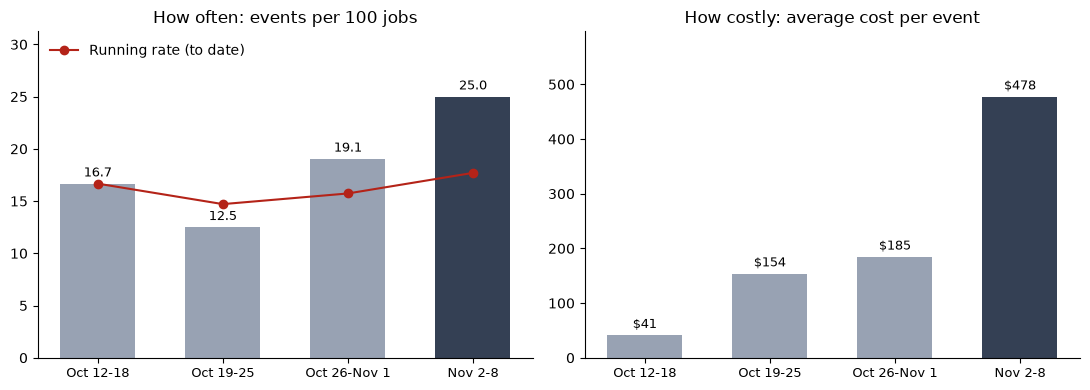

In [6]:
# How often vs how costly, reporting week in dark
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, run, title, fmt in [
        (axes[0], "Events per 100 jobs", "Running events per 100 jobs", "How often: events per 100 jobs", "{:,.1f}"),
        (axes[1], "Avg cost per event ($)", None, "How costly: average cost per event", "${:,.0f}")]:
    vals = rates[col].fillna(0)
    bars = ax.bar(x, vals, color=[GREY] * (len(x) - 1) + [INK], width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in vals], padding=3, fontsize=9)
    if run:
        ax.plot(x, rates[run], color=UP, marker="o", lw=1.5, label="Running rate (to date)")
        ax.legend(frameon=False, loc="upper left")
    ax.set_title(title); ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, vals.max() * 1.25); ax.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.show()

## Chart options: cost per 100 jobs
Four replacements for the multi-line chart in the weekly report, all on real data. The one you pick moves into `reusables.py` and the report.
In every option the dashed mark is the **average of prior weeks**, the benchmark each week is judged against (the same figure as the table's average column).

### Option A: Total only, reporting week colored by whether it beat its average

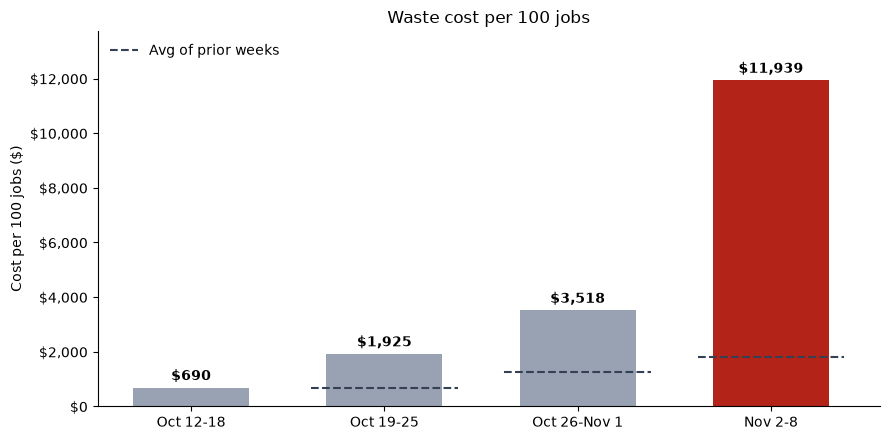

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [GREY] * (len(tot) - 1) + [UP if tot.iloc[-1] > prior_avg.iloc[-1] else DOWN]
bars = ax.bar(x, tot, color=colors, width=0.6)
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in tot], padding=3, fontsize=10, fontweight="bold")
for i, avg in enumerate(prior_avg):
    if pd.notna(avg):
        ax.hlines(avg, i - 0.38, i + 0.38, colors=INK, linestyles="--", lw=1.5,
                  label="Avg of prior weeks" if i == 1 else None)
ax.set_title("Waste cost per 100 jobs"); ax.set_ylabel("Cost per 100 jobs ($)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="upper left")
ax.set_ylim(0, tot.max() * 1.15); plt.tight_layout(); plt.show()

### Option B: Stacked bars, total height plus the mix of types

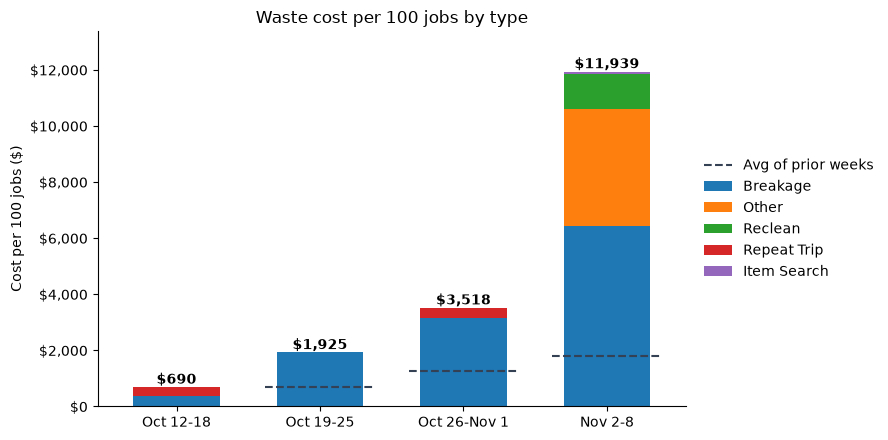

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
per100.set_axis(x).plot(kind="bar", stacked=True, ax=ax, width=0.6, color=plt.cm.tab10.colors, rot=0)
for i, v in enumerate(tot):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
for i, avg in enumerate(prior_avg):
    if pd.notna(avg):
        ax.hlines(avg, i - 0.38, i + 0.38, colors=INK, linestyles="--", lw=1.5,
                  label="Avg of prior weeks" if i == 1 else None)
ax.set_title("Waste cost per 100 jobs by type"); ax.set_ylabel("Cost per 100 jobs ($)"); ax.set_xlabel("")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_ylim(0, tot.max() * 1.12); plt.tight_layout(); plt.show()

### Option C: Small multiples, one small chart per type (each on its own scale)

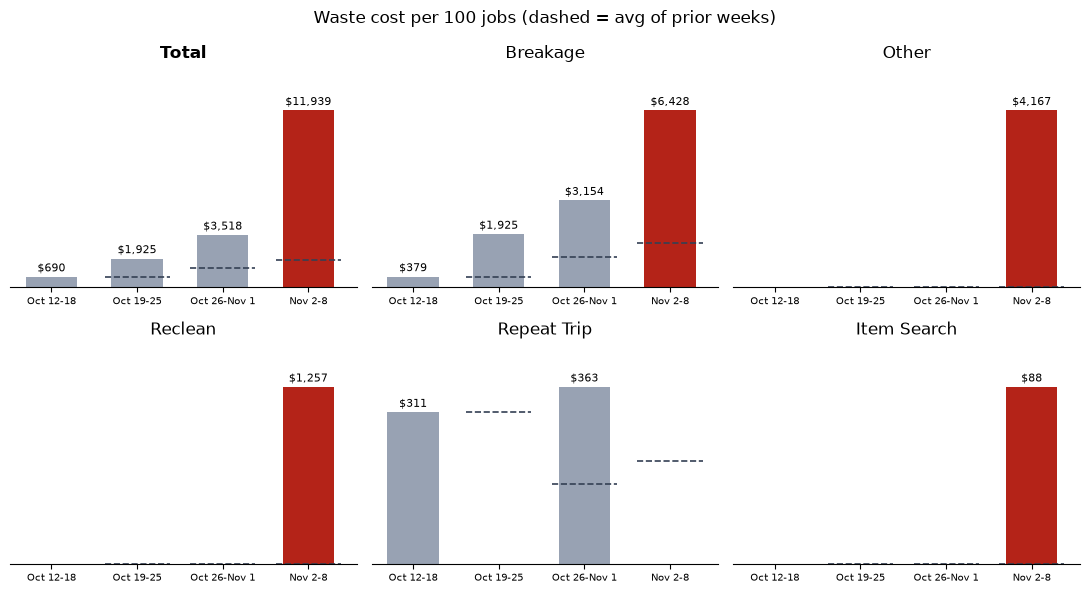

In [9]:
panels = per100.assign(Total=tot)
panel_avg = prior_avg_by_type.assign(Total=prior_avg)
cols = ["Total"] + list(per100.columns)
ncols = 3; nrows = -(-len(cols) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3 * nrows), squeeze=False)
for ax, col in zip(axes.flat, cols):
    vals, avgs = panels[col], panel_avg[col]
    last_up = vals.iloc[-1] > (avgs.iloc[-1] if pd.notna(avgs.iloc[-1]) else 0)
    bars = ax.bar(x, vals, color=[GREY] * (len(x) - 1) + [UP if last_up else DOWN], width=0.6)
    ax.bar_label(bars, labels=[f"${v:,.0f}" if v else "" for v in vals], padding=2, fontsize=8)
    for i, avg in enumerate(avgs):
        if pd.notna(avg):
            ax.hlines(avg, i - 0.38, i + 0.38, colors=INK, linestyles="--", lw=1.2)
    ax.set_title(col, fontweight="bold" if col == "Total" else "normal")
    ax.set_ylim(0, max(vals.max(), avgs.max(skipna=True) if avgs.notna().any() else 0, 1) * 1.25)
    ax.tick_params(axis="x", labelsize=7); ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
for ax in list(axes.flat)[len(cols):]:
    ax.axis("off")
fig.suptitle("Waste cost per 100 jobs (dashed = avg of prior weeks)")
plt.tight_layout(); plt.show()

### Option D: Reporting week vs its average, by type

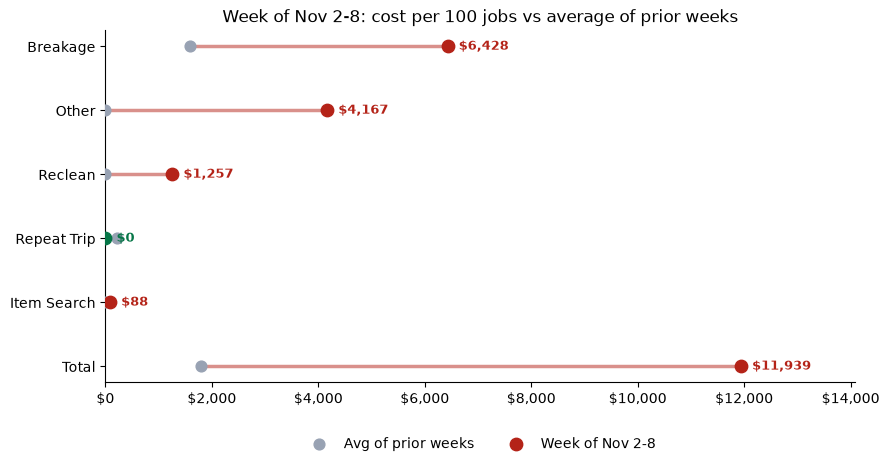

In [10]:
cmp = pd.DataFrame({"avg": prior_avg_by_type.iloc[-1], "now": per100.iloc[-1]}).fillna(0)
cmp.loc["Total"] = [prior_avg.iloc[-1], tot.iloc[-1]]
cmp = cmp.iloc[::-1]                                       # Total on top
fig, ax = plt.subplots(figsize=(9, 0.6 * len(cmp) + 1.2))
for i, (name, r) in enumerate(cmp.iterrows()):
    c = UP if r["now"] > r["avg"] else DOWN
    ax.plot([r["avg"], r["now"]], [i, i], color=c, lw=2.5, alpha=0.5)
    ax.scatter(r["avg"], i, color=GREY, s=60, zorder=3, label="Avg of prior weeks" if i == 0 else None)
    ax.scatter(r["now"], i, color=c, s=80, zorder=3, label=WEEK_LABEL if i == 0 else None)
    ax.annotate(f"${r['now']:,.0f}", (r["now"], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=c, fontweight="bold")
ax.set_yticks(range(len(cmp))); ax.set_yticklabels(cmp.index)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(0, cmp.values.max() * 1.18)
ax.set_title(f"{WEEK_LABEL}: cost per 100 jobs vs average of prior weeks")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()

## Scratch

How much has the percents of how often and how costly waste events are have changed across the three reporting weeks (exclupding baseline)?

,Events per 100 jobs,Avg cost per event ($)
Oct 19-25,-25.00,271.80
Oct 26-Nov 1,52.40,19.90
Nov 2-8,31.20,158.60
Average % change,19.50,150.10
Compound weekly % change,14.50,125.90


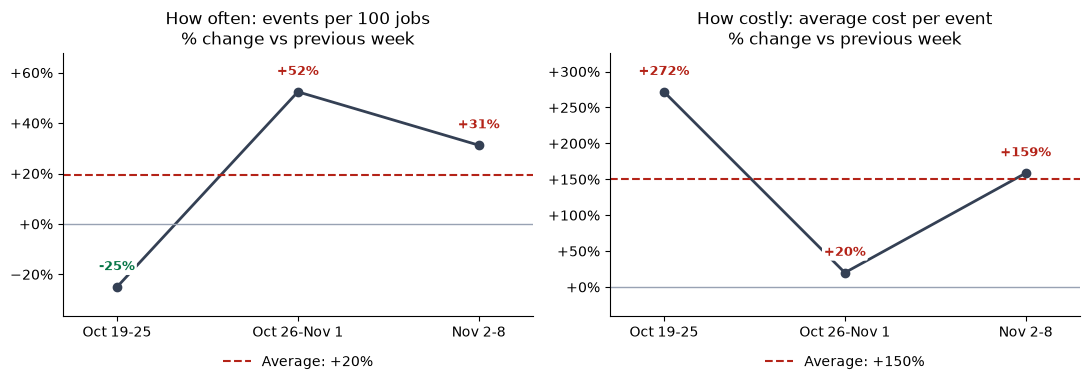

In [11]:
# Week-over-week % change in how often events happen and how much each one costs
cols = {"Events per 100 jobs": "How often: events per 100 jobs",
        "Avg cost per event ($)": "How costly: average cost per event"}
chg_weeks = ["Week of Oct 19-25", "Week of Oct 26-Nov 1", "Week of Nov 2-8"]

pct_change = rates[list(cols)].pct_change().mul(100).loc[chg_weeks]      # each week vs the week before
avg_change = pct_change.mean()                                            # simple average of the 3 changes
start, end = labels.index(chg_weeks[0]) - 1, labels.index(chg_weeks[-1])
compound   = ((rates[list(cols)].iloc[end] / rates[list(cols)].iloc[start]) ** (1 / len(chg_weeks)) - 1) * 100

summary = pd.concat([pct_change.rename(index=short),
                     avg_change.to_frame("Average % change").T,
                     compound.to_frame("Compound weekly % change").T]).round(1)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xs = [short[w] for w in chg_weeks]
for ax, (col, title) in zip(axes, cols.items()):
    vals = pct_change[col]
    ax.plot(xs, vals, color=INK, marker="o", lw=2)
    for xv, v in zip(xs, vals):
        ax.annotate(f"{v:+.0f}%", (xv, v), xytext=(0, 10), textcoords="offset points",
                    ha="center", va="bottom",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"),
                    fontsize=9, fontweight="bold", color=UP if v > 0 else DOWN)
    ax.axhline(avg_change[col], color=UP if avg_change[col] > 0 else DOWN, ls="--", lw=1.5,
               label=f"Average: {avg_change[col]:+.0f}%")
    ax.axhline(0, color=GREY, lw=1)
    ax.set_title(f"{title}\n% change vs previous week")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:+,.0f}%"))
    lo, hi = min(vals.min(), 0), max(vals.max(), 0)
    ax.set_ylim(lo - (hi - lo) * 0.15, hi + (hi - lo) * 0.2)
    ax.set_xlim(-0.3, len(xs) - 0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()